In [2]:
from load_basics import *
from nbodykit.source.catalog import BigFileCatalog
from nbodykit.lab import ArrayCatalog, FFTPower
import h5py, glob
# from astrid_utils import *
from astropy.cosmology import Planck15 as cosmo
from astropy import units

In [2]:
def deltaa_of_a(a, da0=0.01):
    da = da0 * np.power(a, 0.5)
    return da

In [4]:
astart = 0.0111
print(astart)
zstart = 1/(astart) - 1
print(zstart)
print(astart - deltaa_of_a(astart))

0.0111
89.09009009009009
0.010046434624714726


In [6]:
aend = 0.99
zend = 1/aend - 1
print(aend, zend)
print(aend + deltaa_of_a(aend))

0.99 0.010101010101010166
0.9999498743710662


In [10]:
aa = np.linspace(astart, aend, 11)
zz = 1 / aa - 1

dalist = []
dtlist = []
dzlist = []
dlogalist = []

for i, a in enumerate(aa):
    da = deltaa_of_a(a)
    a1 = a - da
    a2 = a + da
    z1 = 1 / a1 - 1
    z2 = 1 / a2 - 1
    dz = z1 - z2
    dt = np.abs(cosmo.age(z1).value - cosmo.age(z2).value)
    dalist.append(da)
    dtlist.append(dt)
    dzlist.append(dz)
    dlogalist.append(np.log(a2/a1))

print()

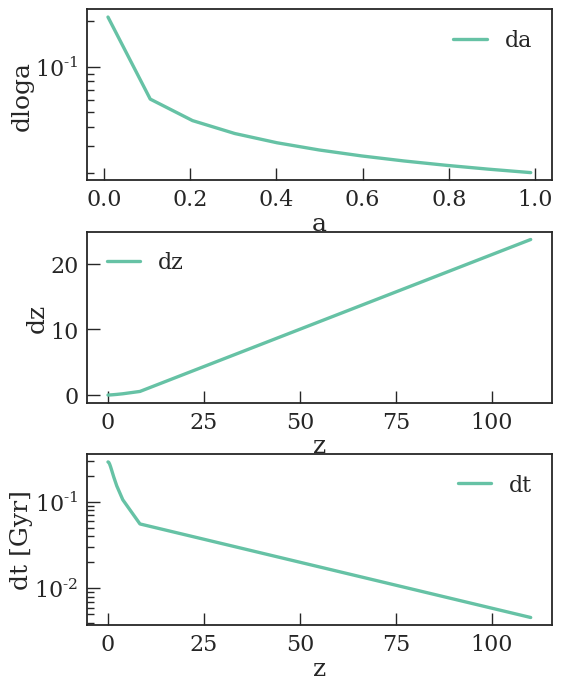

In [11]:
fig, ax = plt.subplots(figsize=(6, 8), ncols=1, nrows=3)
plt.subplots_adjust(hspace=0.3)
ax[0].plot(aa, dlogalist, label='da')
ax[1].plot(zz, dzlist, label='dz')
ax[2].plot(zz, dtlist, label='dt')
ax[0].set_xlabel('a')
ax[1].set_xlabel('z')
ax[2].set_xlabel('z')
ax[0].set_ylabel('dloga')
ax[1].set_ylabel('dz')
ax[2].set_ylabel('dt [Gyr]')

ax[0].set(yscale="log")
ax[2].set(yscale="log")
ax[0].legend()
ax[1].legend()
ax[2].legend()



(5000, 20)


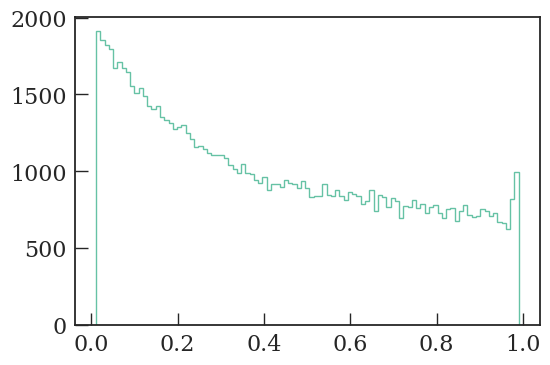

In [6]:
avalues = np.loadtxt("all_avalues.txt")
print(avalues.shape)
bins = np.linspace(0.0111, 0.99, 100)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(avalues.flatten(), bins=bins, histtype='step')
plt.show()